# Unemployment Analysis in India
Data Science | Oasis Infobyte SIP

**Objective:** Explore unemployment data across Indian states to find regional
and monthly trends, and measure the impact of COVID-19 on unemployment rates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [2]:
df = pd.read_csv("Unemployment in India.csv")  
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
print("Shape:", df.shape)
df.info()

Shape: (768, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [4]:
print("Null values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Null values per column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate rows: 27


In [5]:
# 1. Remove stray spaces from column names
df.columns = df.columns.str.strip()

# 2. Remove stray spaces from text values (Region, Frequency, Date strings, etc.)
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# 3. Rename long columns to shorter ones (names missing from your file are ignored)
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour Participation Rate",
    "Region.1": "Zone",
})

# 4. Convert the Date column from text to a real datetime
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# 5. Create month and year columns for later analysis
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month Name"] = df["Date"].dt.strftime("%b")

df.dtypes

Region                               object
Date                         datetime64[ns]
Frequency                            object
Unemployment Rate                   float64
Employed                            float64
Labour Participation Rate           float64
Area                                 object
Year                                float64
Month                               float64
Month Name                           object
dtype: object

In [6]:
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Number of regions:", df["Region"].nunique())
print("Duplicates:", df.duplicated().sum())
print("Nulls:", df.isnull().sum().sum())

Date range: 2019-05-31 to 2020-06-30
Number of regions: 28
Duplicates: 27
Nulls: 280


In [7]:
# Drop rows that are completely empty (no information in any column)
rows_before = len(df)
df = df.dropna(how="all").reset_index(drop=True)
print("Rows removed:", rows_before - len(df))

# Year and Month were floats because of the blank rows, so fix them
df["Year"] = df["Year"].astype(int)
df["Month"] = df["Month"].astype(int)

print("Shape:", df.shape)
print("Nulls:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Regions:", df["Region"].nunique())
print(df["Area"].value_counts())
print(df["Frequency"].value_counts())

Rows removed: 28
Shape: (740, 10)
Nulls: 0
Duplicates: 0
Regions: 28
Area
Urban    381
Rural    359
Name: count, dtype: int64
Frequency
Monthly    740
Name: count, dtype: int64


### Data Overview and Cleaning
- The raw file had 768 rows and 7 columns, covering 28 regions from
  May 2019 to June 2020 (14 monthly readings), split into Rural and Urban areas.
- 28 rows were completely empty (every column null). They also accounted for
  all 27 "duplicate" rows. They carry no information, so I dropped them instead of imputing, leaving 740 rows.
- Column names and text values had leading spaces, which I stripped, and the
  `Date` column was converted from text to datetime.
- After cleaning there are no nulls or duplicates.
- Limitation: the data covers only 14 months, and only a few of them are
  after the COVID-19 lockdown began.

In [8]:
df[["Unemployment Rate", "Employed", "Labour Participation Rate"]].describe()

,Unemployment Rate,Employed,Labour Participation Rate
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [9]:
# Region-wise average unemployment rate (all months, Rural + Urban)
region_avg = (df.groupby("Region")["Unemployment Rate"]
                .mean().sort_values(ascending=False).round(2))
region_avg

Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: Unemployment Rate, dtype: float64

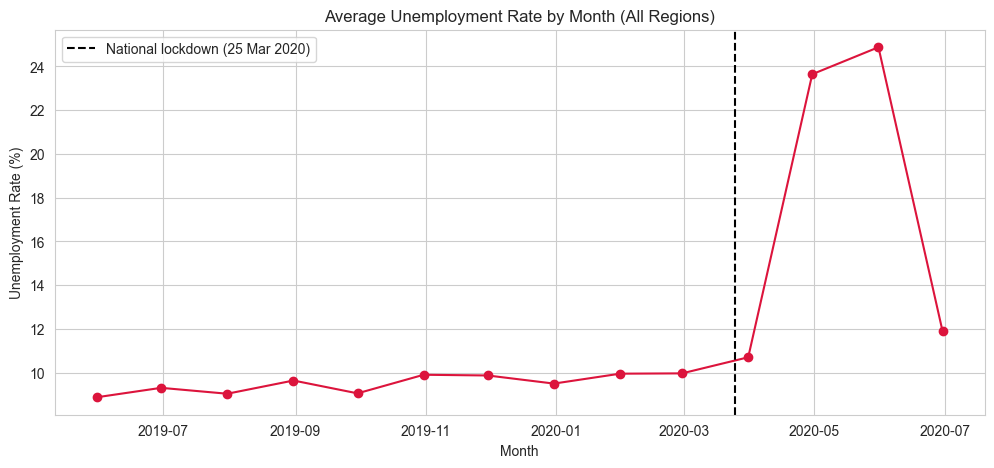

In [10]:
# National month-wise trend: simple average across all regions
monthly = df.groupby("Date")["Unemployment Rate"].mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="crimson")
plt.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--",
            label="National lockdown (25 Mar 2020)")
plt.title("Average Unemployment Rate by Month (All Regions)")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.show()

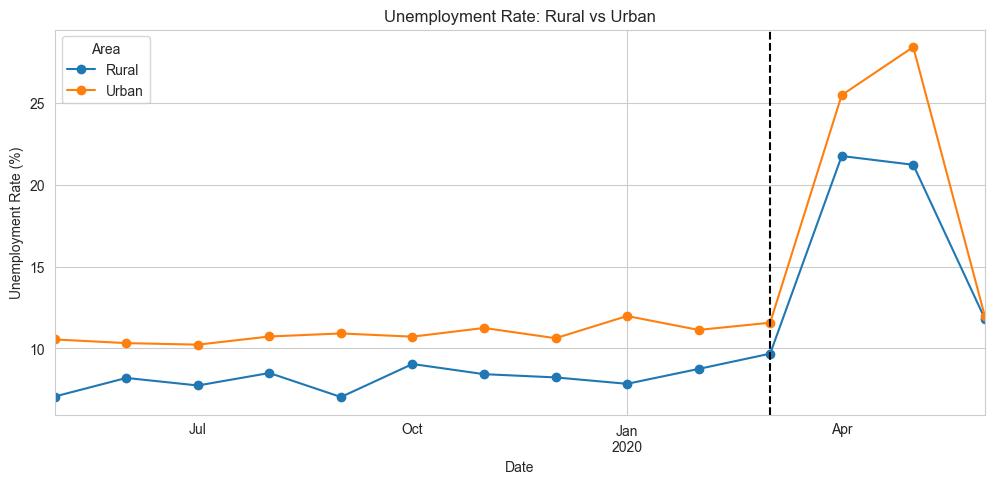

In [11]:
# Rural vs Urban over time
area_month = df.groupby(["Date", "Area"])["Unemployment Rate"].mean().unstack()

area_month.plot(marker="o", figsize=(12, 5))
plt.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--")
plt.title("Unemployment Rate: Rural vs Urban")
plt.ylabel("Unemployment Rate (%)")
plt.show()

### Observations: Monthly Trend
- Before the lockdown, the average unemployment rate stayed fairly stable at
  around 10 %.
- It jumped sharply in May 2020, peaking at about 24%, then began to fall in July.
- Rural and Urban areas both rose, but urban areas were hit harder, with a peak of 25% vs 22%.
- Note: these averages are simple means across regions and are not weighted by population.

Missing from data: []


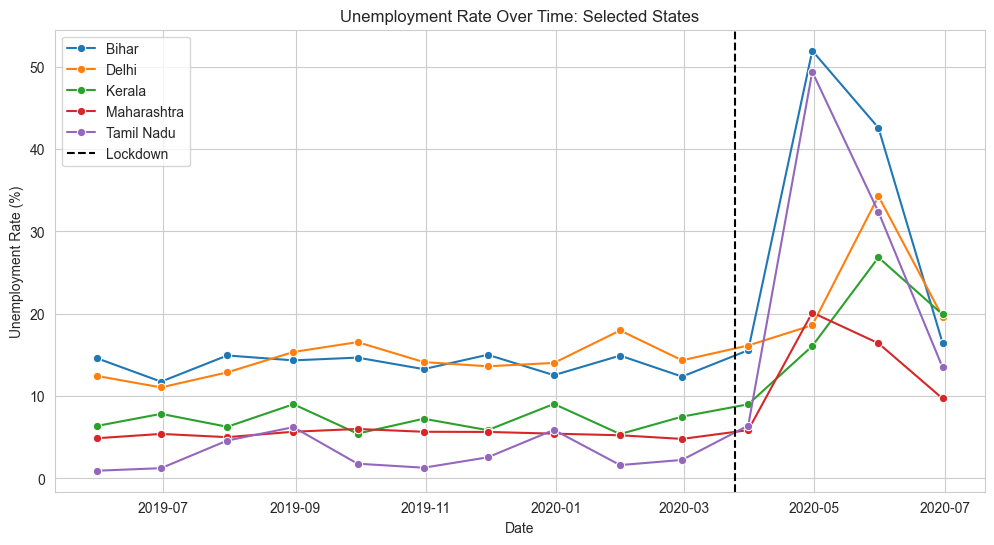

In [12]:
states = ["Maharashtra", "Delhi", "Tamil Nadu", "Bihar", "Kerala"]
print("Missing from data:", [s for s in states if s not in df["Region"].unique()])

state_df = (df[df["Region"].isin(states)]
              .groupby(["Date", "Region"], as_index=False)["Unemployment Rate"].mean())

plt.figure(figsize=(12, 6))
sns.lineplot(data=state_df, x="Date", y="Unemployment Rate", hue="Region", marker="o")
plt.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--", label="Lockdown")
plt.title("Unemployment Rate Over Time: Selected States")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.show()

### Observations: State Trends
- All selected states show a spike in April-May 2020, but the size differs:
  Bihar rose to about 51%, while Kerala rose only to about 15%.
- Before the lockdown, Bihar already had the highest unemployment (around 15%).
- Recovery by June 2020 was fastest in Maharashtra and slowest in Bihar.

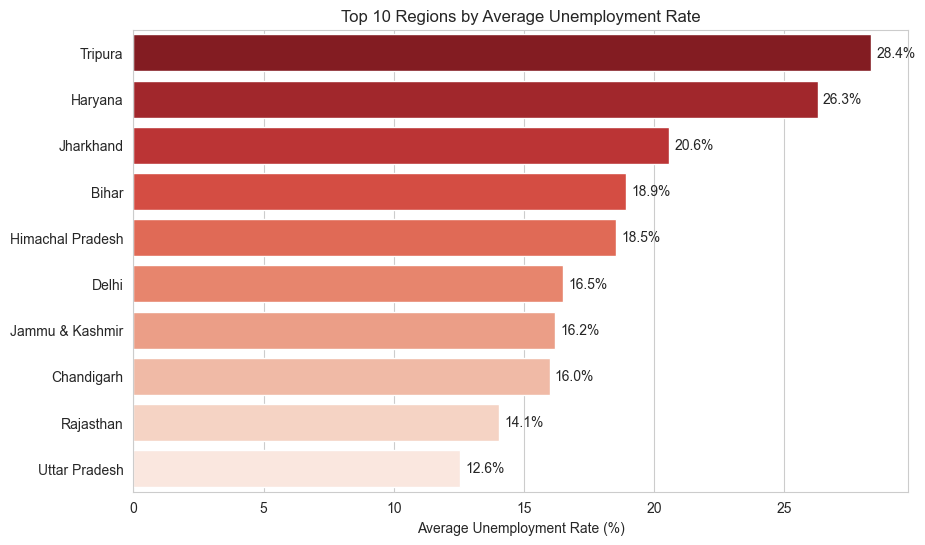

In [13]:
top10 = region_avg.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="Reds_r", legend=False)
for i, v in enumerate(top10.values):
    plt.text(v + 0.2, i, f"{v:.1f}%", va="center")
plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("")
plt.show()

### Observations: Top 10 States
- Tripura has the highest average unemployment at 28%, followed by Haryana and Jharkhand.
- These averages cover the whole period, including the lockdown months, so
  states that were hit hardest in April-May 2020 are pushed up the ranking.

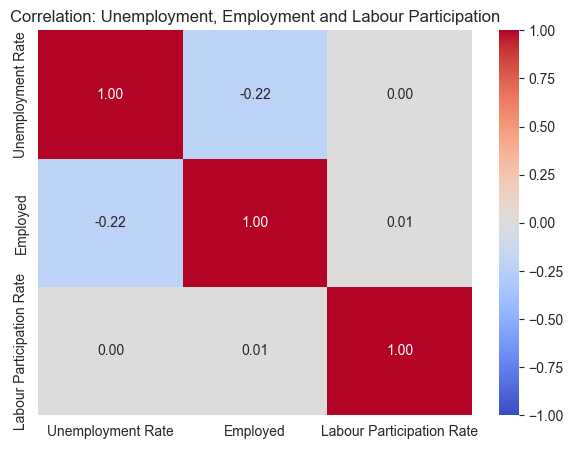

In [14]:
corr = df[["Unemployment Rate", "Employed", "Labour Participation Rate"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation: Unemployment, Employment and Labour Participation")
plt.show()

### Observations: Correlation
- The dataset has an employed *count*, not a rate, and the count depends on
  a state's population, so correlations with it partly reflect state size and not only job conditions.
- Correlation does not imply causation.

In [15]:
lockdown = pd.Timestamp("2020-03-25")
df["Period"] = np.where(df["Date"] < lockdown, "Pre-COVID", "Post-COVID")

print(df.groupby("Period")["Date"].agg(["min", "max", "nunique"]))

                  min        max  nunique
Period                                   
Post-COVID 2020-03-31 2020-06-30        4
Pre-COVID  2019-05-31 2020-02-29       10


In [16]:
period_summary = (df.groupby("Period")[["Unemployment Rate", "Employed", "Labour Participation Rate"]]
                    .mean().round(2).loc[["Pre-COVID", "Post-COVID"]])
period_summary

,Unemployment Rate,Employed,Labour Participation Rate
Period,,,
Pre-COVID,9.51,7466027.87,43.89
Post-COVID,17.77,6517203.34,39.33


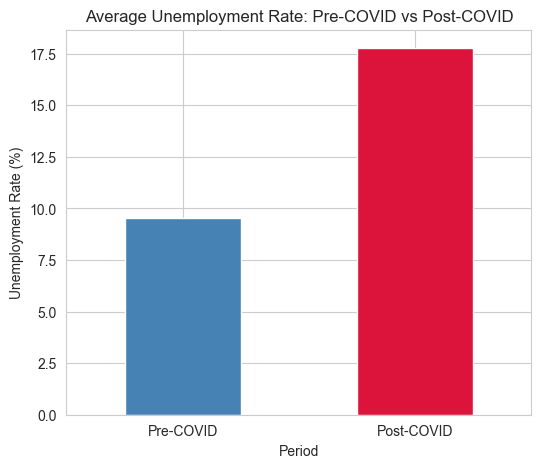

In [17]:

period_summary["Unemployment Rate"].plot(kind="bar", color=["steelblue", "crimson"], rot=0, figsize=(6, 5))
plt.title("Average Unemployment Rate: Pre-COVID vs Post-COVID")
plt.ylabel("Unemployment Rate (%)")
plt.show()

In [18]:
# Which states changed the most?
state_period = (df.pivot_table(index="Region", columns="Period",
                               values="Unemployment Rate", aggfunc="mean")
                  [["Pre-COVID", "Post-COVID"]])
state_period["Change"] = state_period["Post-COVID"] - state_period["Pre-COVID"]
state_period.sort_values("Change", ascending=False).round(2).head(10)

Period,Pre-COVID,Post-COVID,Change
Region,,,
Puducherry,1.59,38.96,37.36
Tamil Nadu,2.84,25.40,22.57
Jharkhand,14.28,36.35,22.07
Bihar,13.83,31.63,17.80
Karnataka,3.23,15.28,12.05
Haryana,22.94,34.65,11.72
Kerala,6.99,17.95,10.96
Telangana,4.66,15.44,10.79
Madhya Pradesh,4.74,14.07,9.33


### Observations: Pre-COVID vs Post-COVID
- The average unemployment rate rose from 9% before the lockdown to 17%
  after it, an increase of 8 percentage points.
- Labour participation changed from 43% to 39%, and the employed count from 7466027.87 to 6517203.34.
- The biggest jumps were in Puducherry, Tamil Nadu and Jharkhand.
- Caveat: the post-COVID period contains only 4 monthly readings, and one is
  March, which was mostly before the lockdown, so the post-COVID average
  is based on a small sample.

## Conclusion
- COVID-19 caused a sharp but temporary rise in unemployment, peaking in May 2020 at 24%.
- The impact was uneven: Puducherry and Tamil Nadu were hit hardest, Andhra Pradesh least.
- Unemployment fell back in June 2020, but it was still more than before the lockdown.
- Data limitations: only 14 months, simple unweighted averages, and Rural/Urban rows are averaged together.